# EcoMaps · Entrenamiento del clasificador de residuos

Aprendizaje por transferencia con **MobileNetV2** sobre TrashNet, exportado a **TensorFlow.js** para correrlo en el navegador (RF-01, RF-08).

**Clases (RF-01, las 6 del documento técnico):** `metal`, `papel_carton`, `plastico`, `vidrio`, `organico`, `no_aprovechable`.
**Datos:** hasta 300 imágenes de entrenamiento y 60 de prueba por clase (TrashNet no tiene orgánicos y `trash` tiene pocas imágenes: ver la carpeta `fotos_propias`). Las de prueba nunca se usan para entrenar.

**Cómo usarlo en Google Colab**
1. Menú *Entorno de ejecución → Cambiar tipo de entorno → GPU* (más rápido).
2. *Entorno de ejecución → Ejecutar todas*. Si Colab pide reiniciar tras instalar las librerías, reinicia y vuelve a ejecutar todo.
3. Al final se descarga `modelo_v1.zip`: descomprímelo en `app/static/modelo/v1/` del proyecto.

In [ ]:
# Keras 2 (tf_keras): el exportador a TensorFlow.js lo necesita. Debe ir ANTES de importar TensorFlow.
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

In [ ]:
%pip install -q tf_keras tensorflowjs datasets pillow scikit-learn huggingface_hub
# tensorflowjs deja instalada una versión vieja de `packaging` que rompe otras librerías: se restaura.
%pip install -q -U "packaging>=23"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
statsmodels 0.15.0 requires packaging>=21.3, but you have packaging 20.9 which is incompatible.
sphinx 8.2.3 requires packaging>=23.0, but you have packaging 20.9 which is incompatible.
pandas-gbq 0.30.0 requires packaging>=22.0.0, but you have packaging 20.9 which is incompatible.
bigquery-magics 0.14.0 requires packaging>=24.2.0, but you have packaging 20.9 which is incompatible.
astropy 7.2.3 requires packaging>=22.0.0, but you have packaging 20.9 which is incompatible.
shap 0.54.1 requires packaging>20.9, but you have packaging 20.9 which is incompatible.
libpysal 4.14.1 requires packaging>=23.2, but you have packaging 20.9 which is incompatible.
db-dtypes 1.9.0 requires packaging>=24.2.0, but you have packaging 20.9 which is incompatible.
langchain-core 1.7.4 requires packaging>=23.2.0, but you have packaging

In [ ]:
import json, random, shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tf_keras as keras
from tf_keras import layers

SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA); tf.random.set_seed(SEMILLA)

# Clase de TrashNet -> clase de EcoMaps
# 'trash' (lo que no se recicla) pasa a ser la clase «no aprovechable» (caneca negra).
MAPA = {"plastic": "plastico", "glass": "vidrio", "metal": "metal",
        "paper": "papel_carton", "cardboard": "papel_carton", "trash": "no_aprovechable"}
CLASES_EXTRA = {"organico"}   # TrashNet no la trae: sale solo de las fotos propias
N_ENTRENAMIENTO, N_PRUEBA = 800, 100
IMG, LOTE = 224, 16
LADO_MAX = 512
DATA = Path("dataset")
UMBRAL = 0.70  # RF-04: por debajo, la página le pregunta al usuario

print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 0. Fotos de orgánicos (opcional pero necesario para las 6 clases)
TrashNet no trae orgánicos. Esta celda descarga **RealWaste** (UCI Machine Learning Repository, licencia **CC BY 4.0**) y copia sus carpetas *Food Organics* (restos de comida) y *Vegetation* (hojas y plantas) a `fotos_propias/organico/`. El cuaderno las mezcla solo con TrashNet en el siguiente paso.

Son fotos tomadas en un relleno sanitario, no en un hogar: sirven para empezar, pero conviene **sumar tus propias fotos** de cáscaras y restos de comida en `fotos_propias/organico/` (el documento pide al menos 80). Si ya tienes esa carpeta con fotos tuyas, la celda las respeta y solo agrega las de RealWaste.

**Cita (inclúyela en el informe):** Single, S., Iranmanesh, S., & Raad, R. (2023). *RealWaste* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5SS4G

In [ ]:
import urllib.request, zipfile, shutil
from pathlib import Path

URL_REALWASTE = "https://archive.ics.uci.edu/static/public/908/realwaste.zip"
CARPETAS_ORGANICO = {"Food Organics", "Vegetation"}
EXT_IMG = {".jpg", ".jpeg", ".png", ".webp"}
destino = Path("fotos_propias") / "organico"
destino.mkdir(parents=True, exist_ok=True)

if any(destino.glob("realwaste_*")):
    print("Ya están las fotos de RealWaste en", destino)
else:
    zip_path = Path("realwaste.zip")
    if not zip_path.exists():
        print("Descargando RealWaste (unos 650 MB, puede tardar unos minutos)…")
        try:
            urllib.request.urlretrieve(URL_REALWASTE, zip_path)
        except Exception as e:
            raise SystemExit(f"No se pudo descargar ({e}).\n"
                             "Descarga realwaste.zip a mano desde https://archive.ics.uci.edu/dataset/908/realwaste, "
                             "súbelo a este mismo panel de archivos y ejecuta esta celda de nuevo.")
    copiadas = 0
    with zipfile.ZipFile(zip_path) as z:
        for nombre in z.namelist():
            partes = Path(nombre).parts
            clase = next((c for c in CARPETAS_ORGANICO if c in partes), None)
            if clase is None or Path(nombre).suffix.lower() not in EXT_IMG:
                continue
            salida = destino / f"realwaste_{clase.replace(' ', '_').lower()}_{Path(nombre).name}"
            with z.open(nombre) as origen, open(salida, "wb") as f:
                shutil.copyfileobj(origen, f)
            copiadas += 1
    print(f"{copiadas} imágenes de RealWaste copiadas a {destino}")
print("Total en fotos_propias/organico:", len(list(destino.iterdir())))

Ya están las fotos de RealWaste en fotos_propias/organico
Total en fotos_propias/organico: 1097


In [ ]:
# Más variedad de orgánicos: comida de Food-101 (se leen solo ~250, sin bajar todo el dataset)
from datasets import load_dataset
destino = Path("fotos_propias") / "organico"
if any(destino.glob("food101_*")):
    print("Ya están las fotos de Food-101")
else:
    try:
        ds = load_dataset("ethz/food101", split="train", streaming=True).shuffle(seed=42, buffer_size=2000)
        n = 0
        for ej in ds:
            im = ej["image"].convert("RGB"); im.thumbnail((512, 512))
            im.save(destino / f"food101_{n:03d}.jpg", quality=85)
            n += 1
            if n >= 250: break
        print(n, "fotos de comida agregadas")
    except Exception as e:
        print("No se pudo usar Food-101 (se puede ignorar):", e)

Ya están las fotos de Food-101


## 1. Dataset
Se descarga TrashNet de Hugging Face (Colab tiene internet) y se arma el reparto entrenamiento/prueba.
**Fotos propias (orgánicos y residuos de Montería):** crea una carpeta `fotos_propias/` junto al cuaderno (en Colab, en el panel de archivos) con una subcarpeta por clase (`organico`, `plastico`, `vidrio`, `papel_carton`, `metal`, `no_aprovechable`) y pon ahí tus fotos. Se mezclan con TrashNet y se reparten igual entre entrenamiento y prueba. El documento pide al menos 80 fotos de orgánicos y 30 propias por clase. Si la carpeta no existe, se ignora.

Si prefieres usar tu propia carpeta o un enlace distinto, cambia `ORIGEN_LOCAL` (carpeta con subcarpetas `cardboard`, `glass`, `metal`, `paper`, `plastic`, `trash`) o el nombre del dataset en la celda.

In [ ]:
# El cargador de Hugging Face (load_dataset) falla con las versiones nuevas de `datasets`
# ("Invalid string class label trashnet@..."). Se baja el zip directamente y se usa ORIGEN_LOCAL.
import zipfile
from huggingface_hub import snapshot_download

ruta = snapshot_download("garythung/trashnet", repo_type="dataset", allow_patterns=["*resized*"])
for z in Path(ruta).rglob("dataset-resized.zip"):
    zipfile.ZipFile(z).extractall("trashnet_raw")
ORIGEN_LOCAL = str(next(Path("trashnet_raw").rglob("cardboard")).parent)
print("Dataset en:", ORIGEN_LOCAL)
DATASET_HF = "garythung/trashnet"  # solo se usa si ORIGEN_LOCAL queda en None
FOTOS_PROPIAS = Path("fotos_propias")  # opcional: fotos de orgánicos y de Montería

from PIL import Image

def reunir():
    """Devuelve {clase_ecomaps: [imagen PIL o ruta, ...]}."""
    grupos = {c: [] for c in sorted(set(MAPA.values()) | CLASES_EXTRA)}
    if ORIGEN_LOCAL:
        for sub in Path(ORIGEN_LOCAL).iterdir():
            clase = MAPA.get(sub.name.lower())
            if clase and sub.is_dir():
                grupos[clase] += [p for p in sub.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}]
    else:
        from datasets import load_dataset
        ds = load_dataset(DATASET_HF)          # igual que en Hugging Face: devuelve un DatasetDict
        print(ds)
        ds = ds["train"] if "train" in ds else ds[list(ds.keys())[0]]
        nombres = ds.features["label"].names
        print("Etiquetas originales:", nombres)
        etiquetas = ds["label"]  # solo las etiquetas: no decodifica todas las imágenes
        for i, e in enumerate(etiquetas):
            clase = MAPA.get(nombres[e].lower())
            if clase:
                grupos[clase].append(i)
        grupos = {c: [(ds, i) for i in idx] for c, idx in grupos.items()}
    # Fotos propias: fotos_propias/<clase>/*.jpg (clases válidas: las de MAPA y organico)
    if FOTOS_PROPIAS.exists():
        for sub in FOTOS_PROPIAS.iterdir():
            if sub.is_dir() and sub.name in grupos:
                grupos[sub.name] += [p for p in sub.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}]
    return grupos

def abrir(item):
    if isinstance(item, tuple):            # (dataset HF, índice)
        return item[0][item[1]]["image"]
    return Image.open(item)

if DATA.exists():
    shutil.rmtree(DATA)
grupos = reunir()
rnd = random.Random(SEMILLA)
for clase, items in sorted(grupos.items()):
    if not items:
        print(f"AVISO: no hay imágenes para «{clase}». Súbelas a fotos_propias/{clase}/ y ejecuta esta celda de nuevo.")
        continue
    rnd.shuffle(items)
    n_prueba = min(N_PRUEBA, len(items) // 5)
    n_entr = min(N_ENTRENAMIENTO, len(items) - n_prueba)
    reparto = {"prueba": items[:n_prueba], "entrenamiento": items[n_prueba:n_prueba + n_entr]}
    for parte, lista in reparto.items():
        carpeta = DATA / parte / clase
        carpeta.mkdir(parents=True, exist_ok=True)
        for k, it in enumerate(lista):
            im = abrir(it).convert("RGB")
            im.thumbnail((LADO_MAX, LADO_MAX))
            im.save(carpeta / f"{clase}_{k:03d}.jpg", quality=85)
    print(f"{clase}: {n_entr} entrenamiento + {n_prueba} prueba (disponibles: {len(items)})")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

Dataset en: trashnet_raw/dataset-resized
metal: 328 entrenamiento + 82 prueba (disponibles: 410)
no_aprovechable: 110 entrenamiento + 27 prueba (disponibles: 137)
organico: 800 entrenamiento + 100 prueba (disponibles: 1097)
papel_carton: 800 entrenamiento + 100 prueba (disponibles: 997)
plastico: 386 entrenamiento + 96 prueba (disponibles: 482)
vidrio: 401 entrenamiento + 100 prueba (disponibles: 501)


## 2. Datos para Keras
El aumento de datos (giros, zoom, contraste) solo se aplica al entrenar. El 15 % del entrenamiento se separa para validar.

In [ ]:
comunes = dict(image_size=(IMG, IMG), batch_size=LOTE, label_mode="categorical", seed=SEMILLA)
train_raw = keras.utils.image_dataset_from_directory(DATA / "entrenamiento", validation_split=0.15, subset="training", **comunes)
val_raw   = keras.utils.image_dataset_from_directory(DATA / "entrenamiento", validation_split=0.15, subset="validation", **comunes)
test_raw  = keras.utils.image_dataset_from_directory(DATA / "prueba", shuffle=False, **comunes)
CLASES = train_raw.class_names           # orden alfabético; se guarda en metadata.json
print("Clases:", CLASES)

prep = keras.applications.mobilenet_v2.preprocess_input   # escala a [-1, 1]; la página hace lo mismo
aumento = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.20),
    layers.RandomZoom(0.25),
    layers.RandomTranslation(0.10, 0.10),
    layers.RandomContrast(0.25),
])
AUTO = tf.data.AUTOTUNE
train = train_raw.map(lambda x, y: (prep(aumento(x, training=True)), y), num_parallel_calls=AUTO).prefetch(AUTO)
val   = val_raw.map(lambda x, y: (prep(x), y), num_parallel_calls=AUTO).prefetch(AUTO)
test  = test_raw.map(lambda x, y: (prep(x), y), num_parallel_calls=AUTO).prefetch(AUTO)

Found 2825 files belonging to 6 classes.
Using 2402 files for training.
Found 2825 files belonging to 6 classes.
Using 423 files for validation.
Found 505 files belonging to 6 classes.
Clases: ['metal', 'no_aprovechable', 'organico', 'papel_carton', 'plastico', 'vidrio']


## 3. Modelo (transferencia desde MobileNetV2)
Primero se entrena solo la capa final; luego se afinan las últimas capas de MobileNetV2 con una tasa de aprendizaje baja.

In [ ]:
base = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")
base.trainable = False

entrada = keras.Input((IMG, IMG, 3))
x = base(entrada, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)
salida = layers.Dense(len(CLASES), activation="softmax")(x)
modelo = keras.Model(entrada, salida)

# Pesos por clase: las que tienen menos fotos (no_aprovechable) cuentan más al entrenar
conteo = {c: len(list((DATA / "entrenamiento" / c).glob("*.jpg"))) for c in CLASES}
total = sum(conteo.values())
pesos = {i: total / (len(CLASES) * conteo[c]) for i, c in enumerate(CLASES)}
print("Fotos de entrenamiento por clase:", conteo)

def callbacks(paciencia):
    return [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=paciencia, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7)]

modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
h1 = modelo.fit(train, validation_data=val, epochs=20, callbacks=callbacks(5), class_weight=pesos)

# Ajuste fino: se liberan las últimas 80 capas (sin tocar las BatchNorm, que se quedan fijas)
base.trainable = True
for capa in base.layers[:-80]:
    capa.trainable = False
for capa in base.layers:
    if isinstance(capa, layers.BatchNormalization):
        capa.trainable = False
modelo.compile(optimizer=keras.optimizers.Adam(3e-5), loss="categorical_crossentropy", metrics=["accuracy"])
h2 = modelo.fit(train, validation_data=val, epochs=30, callbacks=callbacks(6), class_weight=pesos)

Fotos de entrenamiento por clase: {'metal': 328, 'no_aprovechable': 110, 'organico': 800, 'papel_carton': 800, 'plastico': 386, 'vidrio': 401}
Epoch 1/20
151/151 [==============================] - 45s 250ms/step - loss: 1.0636 - accuracy: 0.7002 - val_loss: 0.4900 - val_accuracy: 0.8558 - lr: 0.0010
Epoch 2/20
151/151 [==============================] - 35s 232ms/step - loss: 0.6957 - accuracy: 0.7931 - val_loss: 0.4146 - val_accuracy: 0.8487 - lr: 0.0010
Epoch 3/20
151/151 [==============================] - 36s 233ms/step - loss: 0.6338 - accuracy: 0.8077 - val_loss: 0.3440 - val_accuracy: 0.8723 - lr: 0.0010
Epoch 4/20
151/151 [==============================] - 34s 224ms/step - loss: 0.6184 - accuracy: 0.8201 - val_loss: 0.4326 - val_accuracy: 0.8392 - lr: 0.0010
Epoch 5/20
151/151 [==============================] - 35s 227ms/step - loss: 0.5430 - accuracy: 0.8368 - val_loss: 0.3755 - val_accuracy: 0.8723 - lr: 0.0010
Epoch 6/20
151/151 [==============================] - 34s 223ms/ste

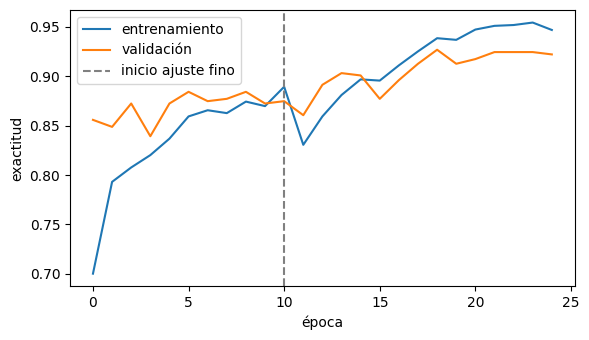

In [ ]:
acc = h1.history["accuracy"] + h2.history["accuracy"]
vacc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
plt.figure(figsize=(6, 3.5))
plt.plot(acc, label="entrenamiento"); plt.plot(vacc, label="validación")
plt.axvline(len(h1.history["accuracy"]) - 1, ls="--", c="gray", label="inicio ajuste fino")
plt.xlabel("época"); plt.ylabel("exactitud"); plt.legend(); plt.tight_layout()
plt.savefig("curvas_entrenamiento.png", dpi=150); plt.show()

## 4. Evaluación con las imágenes de prueba (RF-08)
Estas imágenes no se usaron para entrenar. Meta orientativa: exactitud ≥ 80 %.

32/32 [==============================] - 3s 61ms/step
Exactitud global: 88.9%  (449 de 505 imágenes de prueba)

                 precision    recall  f1-score   support

          metal      0.846     0.939     0.890        82
no_aprovechable      0.680     0.630     0.654        27
       organico      1.000     0.990     0.995       100
   papel_carton      0.920     0.920     0.920       100
       plastico      0.853     0.844     0.848        96
         vidrio      0.874     0.830     0.851       100

       accuracy                          0.889       505
      macro avg      0.862     0.859     0.860       505
   weighted avg      0.889     0.889     0.889       505



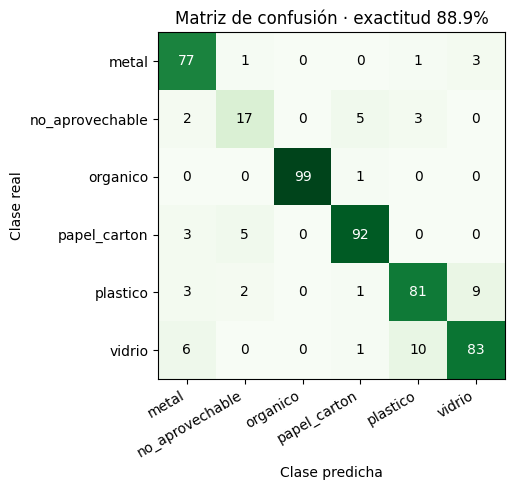

Confusiones más frecuentes (real -> predicha): [('vidrio', 'plastico', 10), ('plastico', 'vidrio', 9), ('vidrio', 'metal', 6), ('no_aprovechable', 'papel_carton', 5), ('papel_carton', 'no_aprovechable', 5)]
Predicciones con confianza < 70% (la página pregunta al usuario): 11.5%


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

y_true = np.concatenate([y.numpy().argmax(1) for _, y in test])
probs = modelo.predict(test)
y_pred = probs.argmax(1)
exactitud = float((y_true == y_pred).mean())
print(f"Exactitud global: {exactitud:.1%}  ({int((y_true == y_pred).sum())} de {len(y_true)} imágenes de prueba)\n")
print(classification_report(y_true, y_pred, target_names=CLASES, digits=3))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(cm, cmap="Greens")
ax.set_xticks(range(len(CLASES))); ax.set_xticklabels(CLASES, rotation=30, ha="right")
ax.set_yticks(range(len(CLASES))); ax.set_yticklabels(CLASES)
ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real"); ax.set_title(f"Matriz de confusión · exactitud {exactitud:.1%}")
for i in range(len(CLASES)):
    for j in range(len(CLASES)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.savefig("matriz_confusion.png", dpi=150); plt.show()

# Pares que más se confunden (para el informe: qué se hizo para mejorarlos)
confusiones = [(CLASES[i], CLASES[j], int(cm[i, j])) for i in range(len(CLASES)) for j in range(len(CLASES)) if i != j and cm[i, j] > 0]
confusiones.sort(key=lambda t: -t[2])
print("Confusiones más frecuentes (real -> predicha):", confusiones[:5])

# Cuántas predicciones quedarían bajo el umbral y la página preguntaría al usuario
dudosas = float((probs.max(1) < UMBRAL).mean())
print(f"Predicciones con confianza < {UMBRAL:.0%} (la página pregunta al usuario): {dudosas:.1%}")

json.dump({"exactitud": exactitud, "clases": CLASES, "matriz_confusion": cm.tolist(),
           "imagenes_prueba": int(len(y_true)), "confusiones_top": confusiones[:5], "pct_bajo_umbral": dudosas},
          open("informe_evaluacion.json", "w"), indent=2, ensure_ascii=False)

## 5. Exportar a TensorFlow.js
Genera `model.json`, los archivos `.bin` y `metadata.json` (con el nombre de cada clase, en el mismo orden que usa el modelo).

In [ ]:
import sys, types
import numpy as np

# Copia de seguridad del modelo entrenado
modelo.save("modelo_respaldo.h5")

# 1) tensorflowjs usa alias de NumPy que ya no existen
for _n, _t in {"object": object, "bool": bool, "int": int, "float": float, "complex": complex, "str": str}.items():
    if not hasattr(np, _n):
        setattr(np, _n, _t)

# 2) tensorflow_hub (que carga tensorflowjs) usa tf.estimator, ya eliminado. Para convertir
#    un modelo de Keras no hace falta: se reemplaza por un módulo vacío.
for _k in [k for k in sys.modules if k.startswith(("tensorflowjs", "tensorflow_hub"))]:
    del sys.modules[_k]          # limpia un intento fallido anterior
sys.modules["tensorflow_hub"] = types.ModuleType("tensorflow_hub")

import tensorflowjs as tfjs

SALIDA = Path("modelo_v1")
if SALIDA.exists():
    shutil.rmtree(SALIDA)
tfjs.converters.save_keras_model(modelo, str(SALIDA))
json.dump({"labels": CLASES, "imageSize": IMG, "preprocess": "x/127.5 - 1", "umbral": UMBRAL, "version": "v1"},
          open(SALIDA / "metadata.json", "w"), indent=2, ensure_ascii=False)

print("Archivos exportados:")
for f in sorted(SALIDA.iterdir()):
    print(f"  {f.name}  {f.stat().st_size / 1e6:.2f} MB")

shutil.make_archive("modelo_v1", "zip", SALIDA)

/usr/local/lib/python3.13/dist-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(
/tmp/ipykernel_18277/749990970.py:9: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, _n):
/tmp/ipykernel_18277/749990970.py:9: FutureWarning: In the future `np.str` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, _n):


Archivos exportados:
  group1-shard1of3.bin  4.19 MB
  group1-shard2of3.bin  4.19 MB
  group1-shard3of3.bin  1.96 MB
  metadata.json  0.00 MB
  model.json  0.12 MB


'/content/modelo_v1.zip'

In [ ]:
# Descarga el modelo y los resultados (en Colab). Descomprime modelo_v1.zip en app/static/modelo/v1/
try:
    from google.colab import files
    for f in ["modelo_v1.zip", "matriz_confusion.png", "informe_evaluacion.json", "curvas_entrenamiento.png"]:
        files.download(f)
except ImportError:
    print("Fuera de Colab: los archivos quedaron en la carpeta actual.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Prueba con una imagen nueva (opcional)
Sube una foto de un residuo y mira qué responde, con la misma regla de la página: si la confianza es menor al 70 %, muestra las 2 opciones más probables.

Saving OIP (1).webp to OIP (1) (1).webp
OIP (1) (1).webp: metal (87%)


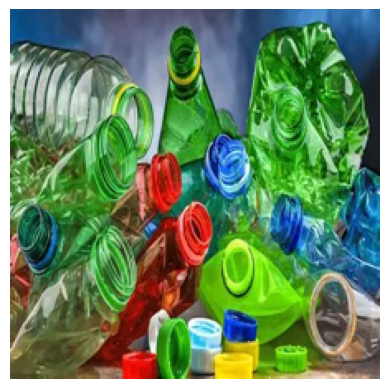

In [ ]:
from google.colab import files
subida = files.upload()
for nombre in subida:
    im = Image.open(nombre).convert("RGB").resize((IMG, IMG))
    x = prep(np.array(im, dtype="float32"))[None]
    p = modelo.predict(x, verbose=0)[0]
    orden = p.argsort()[::-1]
    if p[orden[0]] >= UMBRAL:
        print(f"{nombre}: {CLASES[orden[0]]} ({p[orden[0]]:.0%})")
    else:
        print(f"{nombre}: no estoy seguro -> {CLASES[orden[0]]} ({p[orden[0]]:.0%}) o {CLASES[orden[1]]} ({p[orden[1]]:.0%})")
    plt.imshow(im); plt.axis("off"); plt.show()